In [100]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer


In [101]:
df=pd.read_csv('titanic_toy.csv')

In [102]:
df.head()

,Age,Fare,Family,Survived
0,22.0,7.2500,1,0
1,38.0,71.2833,1,1
2,26.0,7.9250,0,1
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


In [103]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Age       714 non-null    float64
 1   Fare      846 non-null    float64
 2   Family    891 non-null    int64  
 3   Survived  891 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 28.0 KB


In [104]:
df.isnull().mean()

Age         0.198653
Fare        0.050505
Family      0.000000
Survived    0.000000
dtype: float64

# Using Pandas

In [105]:
x=df.drop(columns=['Survived'])
y=df['Survived']

In [106]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=2)

In [107]:
x_train.shape,x_test.shape

((712, 3), (179, 3))

In [108]:
x_train.isnull().mean()

Age       0.207865
Fare      0.050562
Family    0.000000
dtype: float64

In [109]:
mean_age=x_train['Age'].mean()
median_age=x_train['Age'].median()

mean_fare=x_train['Fare'].mean()
median_fare=x_train['Fare'].median()

In [110]:
x_train['Age_mean']=x_train['Age'].fillna(mean_age)
x_train['Age_median']=x_train['Age'].fillna(median_age)

x_train['Fare_mean']=x_train['Fare'].fillna(mean_age)
x_train['Fare_median']=x_train['Fare'].fillna(median_age)

In [111]:
x_train.sample(5)

,Age,Fare,Family,Age_mean,Age_median,Fare_mean,Fare_median
390,36.0,120.0000,3,36.000000,36.00,120.0000,120.0000
203,45.5,7.2250,0,45.500000,45.50,7.2250,7.2250
277,NaN,0.0000,0,29.785904,28.75,0.0000,0.0000
450,36.0,27.7500,3,36.000000,36.00,27.7500,27.7500
477,29.0,7.0458,1,29.000000,29.00,7.0458,7.0458


In [112]:
print("Original Age variable variance",x_train['Age'].var())
print("Age variable variance aftr mean imputation",x_train['Age_mean'].var())
print(" Age variable variance aftr median imputation",x_train['Age_median'].var())

print("Original Fare variable variance",x_train['Fare'].var())
print("Fare variable variance aftr mean imputation",x_train['Fare_mean'].var())
print("Fare variable variance aftr median imputation",x_train['Fare_median'].var())

Original Age variable variance 204.3495133904614
Age variable variance aftr mean imputation 161.81262452718673
 Age variable variance aftr median imputation 161.9895663346054
Original Fare variable variance 2448.197913706318
Fare variable variance aftr mean imputation 2324.623996772905
Fare variable variance aftr median imputation 2324.9576136149317


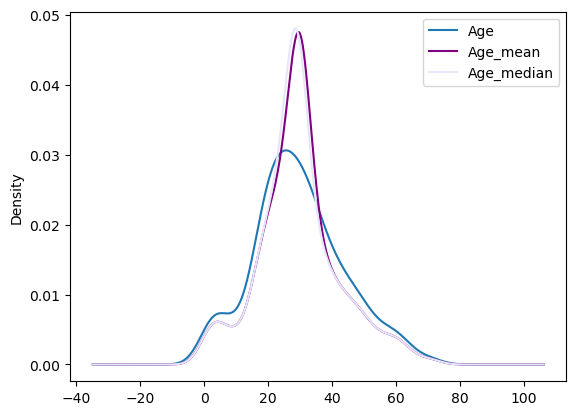

In [113]:
fig=plt.figure()
ax=fig.add_subplot(111)

# original age distribution
x_train["Age"].plot(kind='kde',ax=ax)

#distribution of variable imputed with the mean
x_train["Age_mean"].plot(kind='kde',ax=ax,color='purple')

#distribution of variable imputed with the median
x_train["Age_median"].plot(kind='kde',ax=ax,color='lavender')

#ads legends
lines,labels=ax.get_legend_handles_labels()
ax.legend(lines,labels,loc='best')

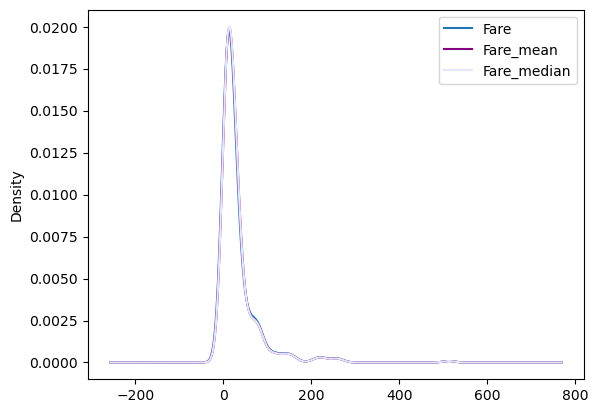

In [114]:
fig=plt.figure()
ax=fig.add_subplot(111)

# original age distribution
x_train["Fare"].plot(kind='kde',ax=ax)

#distribution of variable imputed with the mean
x_train["Fare_mean"].plot(kind='kde',ax=ax,color='purple')

#distribution of variable imputed with the median
x_train["Fare_median"].plot(kind='kde',ax=ax,color='lavender')

#ads legends
lines,labels=ax.get_legend_handles_labels()
ax.legend(lines,labels,loc='best')

In [115]:
x_train.cov()

,Age,Fare,Family,Age_mean,Age_median,Fare_mean,Fare_median
Age,204.349513,70.719262,-6.498901,204.349513,204.349513,66.383530,66.280487
Fare,70.719262,2448.197914,17.258917,55.603719,57.957599,2448.197914,2448.197914
Family,-6.498901,17.258917,2.735252,-5.146106,-5.112563,16.399278,16.404484
Age_mean,204.349513,55.603719,-5.146106,161.812625,161.812625,52.565299,52.483705
Age_median,204.349513,57.957599,-5.112563,161.812625,161.989566,54.793876,54.710043
Fare_mean,66.383530,2448.197914,16.399278,52.565299,54.793876,2324.623997,2324.765012
Fare_median,66.280487,2448.197914,16.404484,52.483705,54.710043,2324.765012,2324.957614


In [116]:
x_train.corr()

,Age,Fare,Family,Age_mean,Age_median,Fare_mean,Fare_median
Age,1.000000,0.092644,-0.299113,1.000000,1.000000,0.089754,0.089604
Fare,0.092644,1.000000,0.208268,0.088069,0.091757,1.000000,1.000000
Family,-0.299113,0.208268,1.000000,-0.244610,-0.242883,0.205660,0.205710
Age_mean,1.000000,0.088069,-0.244610,1.000000,0.999454,0.085707,0.085568
Age_median,1.000000,0.091757,-0.242883,0.999454,1.000000,0.089292,0.089149
Fare_mean,0.089754,1.000000,0.205660,0.085707,0.089292,1.000000,0.999989
Fare_median,0.089604,1.000000,0.205710,0.085568,0.089149,0.999989,1.000000


<Axes: >

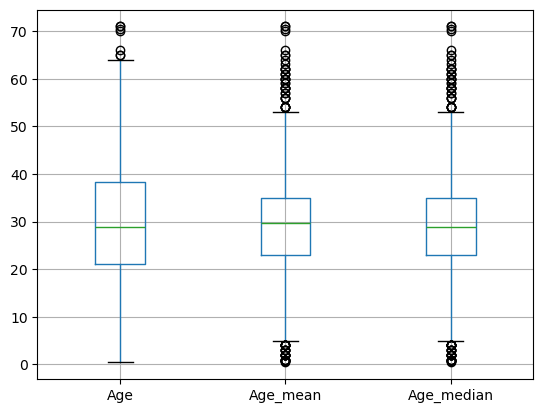

In [117]:
 x_train[['Age','Age_mean','Age_median']].boxplot()

<Axes: >

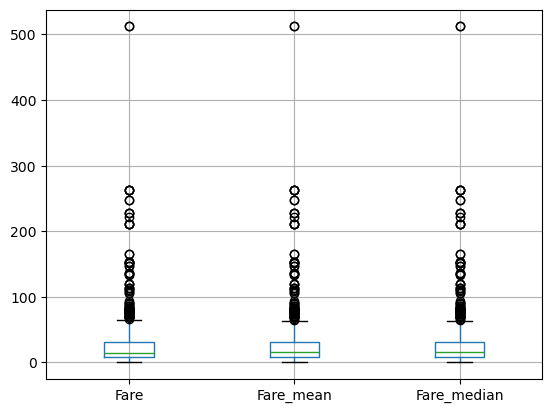

In [118]:
 x_train[['Fare','Fare_mean','Fare_median']].boxplot()

# Using Sklearn

In [119]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=2)

## Different columns may need different imputation strategies.

For Age, we want to replace missing values with the median (since age data is often skewed).

For Fare, we to replace missing values with the mean (since fares are usually closer to normal distribution).

That’s why you create two separate imputer objects:

In [120]:
#we are applying differrent strategies in different column  for the same data
imputer1=SimpleImputer(strategy='median')
imputer2=SimpleImputer(strategy ='mean')

## Then you assign them separately inside the ColumnTransformer:

In [121]:
# ColumnTransformer is used to apply different preprocessing (like imputation, scaling, encoding, etc.)
# to different columns of a dataset.

trf = ColumnTransformer([

    # Apply imputer1 (say, SimpleImputer with mean/median) on the "Age" column
    ('imputer1', imputer1, ['Age']),  

    # Apply imputer2 (say, SimpleImputer with mean) on the "Fare" column
    ('imputer2', imputer2, ['Fare'])  

], remainder='passthrough')  

# remainder='passthrough' means:
# → Columns not mentioned (other than Age and Fare) will be kept as they are (unchanged).
# If we set remainder='drop', then only Age and Fare would remain in the transformed dataset.


In [122]:
trf.fit(x_train)

C:\Users\banik\anaconda3\Lib\site-packages\sklearn\compose\_column_transformer.py:1623: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


ColumnTransformer(remainder='passthrough',
                  transformers=[('imputer1', SimpleImputer(strategy='median'),
                                 ['Age']),
                                ('imputer2', SimpleImputer(), ['Fare'])])

In [127]:
# After fitting the ColumnTransformer 'trf' on your dataset,
# you can access the individual transformers inside it using 'named_transformers_'.

trf.named_transformers_['imputer1'].statistics_

array([28.75])

##  This line fetches the imputation value (mean/median/etc.) that 'imputer1' learned for the "Age" column.

In [124]:
trf.named_transformers_['imputer2'].statistics_

array([32.61759689])

## This replaces missing values in "Age" and "Fare" with the learned values (e.g., median=28 for Age, mean=32.2 for Fare).
 x_train → gets imputed (missing values filled) using training set statistics.

 x_test → gets imputed using the same values learned from training, ensuring no data leakage.

In [125]:
# Applies the transformations defined in trf (imputation in this case).
x_train=trf.transform(x_train)
x_test=trf.transform(x_test)

In [126]:
x_train

array([[ 40.    ,  27.7208,   0.    ],
       [  4.    ,  16.7   ,   2.    ],
       [ 47.    ,   9.    ,   0.    ],
       ...,
       [ 71.    ,  49.5042,   0.    ],
       [ 28.75  , 221.7792,   0.    ],
       [ 28.75  ,  25.925 ,   0.    ]])